# 모두마켓 웹 로그 분석 — 종합 실습

가상 웹 서버 접속 로그 1,500줄을 정규식으로 파싱하고, 상태 코드·경로·시간대별로 집계합니다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 0. 웹 서버 접속 로그 생성 (가상)
한 줄이 통째로 문자열인 로그를 만듭니다.

In [2]:
np.random.seed(7)
n_logs = 1500
ips = [f"203.0.113.{k}" for k in range(1, 60)] + [f"198.51.100.{k}" for k in range(1, 60)]
paths = ["/", "/products", "/products/123", "/products/456", "/cart",
         "/checkout", "/login", "/search", "/api/orders"]
methods = ["GET", "GET", "GET", "POST"]
statuses = [200, 200, 200, 200, 200, 404, 500, 301]

# 시각: 7일치, 초 단위로 무작위 발생 후 정렬
log_times = pd.to_datetime("2025-03-01") + pd.to_timedelta(
    np.sort(np.random.randint(0, 7 * 24 * 3600, n_logs)), unit="s")

lines = []
for i in range(n_logs):
    ip = np.random.choice(ips)
    ts_str = log_times[i].strftime("%d/%b/%Y:%H:%M:%S")   # 12/Jan/2025:10:15:32
    m = np.random.choice(methods)
    p = np.random.choice(paths)
    st = np.random.choice(statuses)
    sz = np.random.randint(200, 5000)
    lines.append(f'{ip} - - [{ts_str}] "{m} {p} HTTP/1.1" {st} {sz}')

web_logs = pd.DataFrame({"raw": lines})
print("웹 로그 생성 완료:", web_logs.shape)
print("\n[원본 로그 한 줄은 이렇게 생겼습니다]")
for line in web_logs["raw"].head(3):
    print(line)

웹 로그 생성 완료: (1500, 1)

[원본 로그 한 줄은 이렇게 생겼습니다]
203.0.113.39 - - [01/Mar/2025:00:01:14] "GET / HTTP/1.1" 200 2371
198.51.100.21 - - [01/Mar/2025:00:02:24] "GET / HTTP/1.1" 301 284
198.51.100.17 - - [01/Mar/2025:00:02:28] "GET /search HTTP/1.1" 200 1448


## 시나리오 1 — 정규식으로 6개 필드를 한 번에 추출

In [3]:
pattern = (
    r"(?P<ip>\d+\.\d+\.\d+\.\d+)"        # IP: 숫자.숫자.숫자.숫자
    r" - - \["                            # 고정 구분 부분
    r"(?P<ts>[^\]]+)"                     # 시각: ] 가 아닌 글자들
    r"\] \""                              # ] 와 따옴표
    r"(?P<method>\w+) "                   # 방식: GET/POST
    r"(?P<path>\S+)"                      # 경로: 공백 아닌 글자들
    r"[^\"]*\" "                          # HTTP/1.1 부분 건너뛰기
    r"(?P<status>\d+) "                   # 상태 코드
    r"(?P<size>\d+)"                      # 응답 크기
)
logs = web_logs["raw"].str.extract(pattern)
print("추출된 표:", logs.shape)
print(logs.head())
print("\n추출 실패(어느 한 칸이라도 NaN) 행 수:", logs.isna().any(axis=1).sum())

추출된 표: (1500, 6)
              ip                    ts method       path status  size
0   203.0.113.39  01/Mar/2025:00:01:14    GET          /    200  2371
1  198.51.100.21  01/Mar/2025:00:02:24    GET          /    301   284
2  198.51.100.17  01/Mar/2025:00:02:28    GET    /search    200  1448
3   203.0.113.35  01/Mar/2025:00:03:56    GET      /cart    404  3921
4   203.0.113.47  01/Mar/2025:00:14:29    GET  /products    500  2580

추출 실패(어느 한 칸이라도 NaN) 행 수: 0


## 시나리오 2 — 타입 정리(날짜·숫자) + dt 부품

In [4]:
logs["ts"] = pd.to_datetime(logs["ts"], format="%d/%b/%Y:%H:%M:%S", errors="coerce")
print("시각 파싱 실패(NaT) 건수:", logs["ts"].isna().sum())
print("기간:", logs["ts"].min(), "~", logs["ts"].max())

logs["status"] = logs["status"].astype(int)
logs["size"] = logs["size"].astype(int)

# dt 부품: 시각(hour)과 요일
logs["hour"] = logs["ts"].dt.hour
logs["dow_name"] = logs["ts"].dt.day_name()

print("\n정리 후 자료형:")
print(logs.dtypes)
print()
print(logs[["ip", "ts", "method", "path", "status", "hour", "dow_name"]].head())

시각 파싱 실패(NaT) 건수: 0
기간: 2025-03-01 00:01:14 ~ 2025-03-07 23:42:41

정리 후 자료형:
ip                     str
ts          datetime64[us]
method                 str
path                   str
status               int64
size                 int64
hour                 int32
dow_name               str
dtype: object

              ip                  ts method       path  status  hour  dow_name
0   203.0.113.39 2025-03-01 00:01:14    GET          /     200     0  Saturday
1  198.51.100.21 2025-03-01 00:02:24    GET          /     301     0  Saturday
2  198.51.100.17 2025-03-01 00:02:28    GET    /search     200     0  Saturday
3   203.0.113.35 2025-03-01 00:03:56    GET      /cart     404     0  Saturday
4   203.0.113.47 2025-03-01 00:14:29    GET  /products     500     0  Saturday


### 상태 코드·인기 경로 빠르게 집계

In [5]:
print("[상태 코드 분포]")
print(logs["status"].value_counts())

error_rate = (logs["status"] >= 400).mean() * 100   # 4xx·5xx 비율
print(f"\n오류 응답(4xx·5xx) 비율: {error_rate:.1f}%")

print("\n[요청 방식 분포]")
print(logs["method"].value_counts())

print("\n[요청이 많은 경로 TOP 5]")
print(logs["path"].value_counts().head())

[상태 코드 분포]
status
200    964
301    188
404    178
500    170
Name: count, dtype: int64

오류 응답(4xx·5xx) 비율: 23.2%

[요청 방식 분포]
method
GET     1157
POST     343
Name: count, dtype: int64

[요청이 많은 경로 TOP 5]
path
/                184
/search          175
/cart            173
/products/456    171
/products        168
Name: count, dtype: int64


## 시나리오 3 — 시간대별 트래픽 (resample 'h')

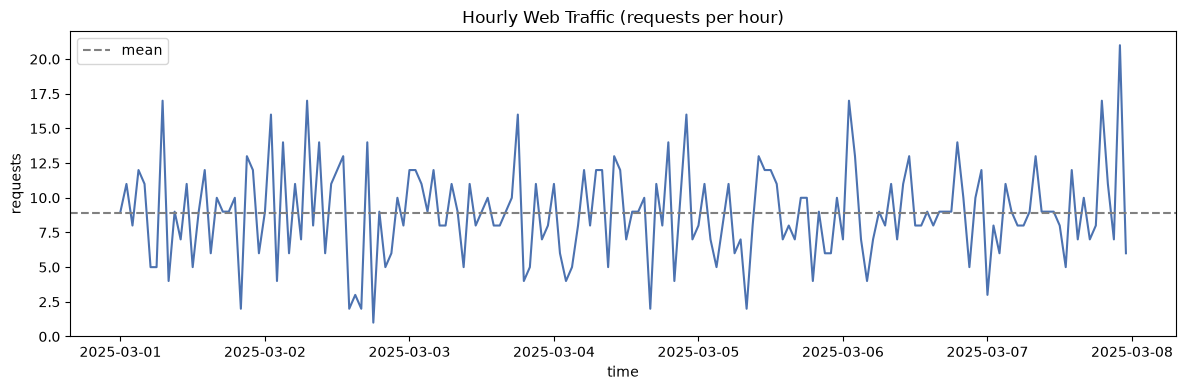

시간당 평균 요청 수: 8.9건
가장 트래픽이 많았던 시간대 TOP 3:
ts
2025-03-07 22:00:00    21
2025-03-02 07:00:00    17
2025-03-06 01:00:00    17
Name: ip, dtype: int64


In [6]:
log_ts = logs.dropna(subset=["ts"]).set_index("ts").sort_index()
hourly_traffic = log_ts["ip"].resample("h").count()    # 시간당 요청 수

plt.figure(figsize=(12, 4))
plt.plot(hourly_traffic.index, hourly_traffic.values, color="#4C72B0")
plt.axhline(hourly_traffic.mean(), color="gray", linestyle="--", label="mean")
plt.title("Hourly Web Traffic (requests per hour)")
plt.xlabel("time"); plt.ylabel("requests"); plt.legend()
plt.tight_layout(); plt.show()

print(f"시간당 평균 요청 수: {hourly_traffic.mean():.1f}건")
print("가장 트래픽이 많았던 시간대 TOP 3:")
print(hourly_traffic.sort_values(ascending=False).head(3))

### 시각(hour)·요일별 패턴

In [7]:
print("[시각(hour)별 요청 수]")
print(logs["hour"].value_counts().sort_index().to_string())

print("\n[요일별 요청 수]")
print(logs["dow_name"].value_counts())

[시각(hour)별 요청 수]
hour
0     59
1     81
2     53
3     63
4     58
5     62
6     51
7     81
8     59
9     57
10    70
11    76
12    61
13    65
14    59
15    50
16    49
17    70
18    61
19    72
20    46
21    58
22    82
23    57

[요일별 요청 수]
dow_name
Thursday     225
Monday       221
Friday       221
Tuesday      215
Saturday     212
Sunday       208
Wednesday    198
Name: count, dtype: int64


### 다음 분석 근거 — 경로별 오류율, 오류가 많은 IP

In [8]:
logs["is_error"] = logs["status"] >= 400
print("[경로별 오류율(%)]")
print(logs.groupby("path")["is_error"].mean().mul(100).round(1).sort_values(ascending=False))

print("\n[오류 응답이 많은 IP TOP 3]")
print(logs[logs["is_error"]]["ip"].value_counts().head(3))

ip = "203.0.113.58"
print(f"\n{ip} 전체 요청 수:", (logs["ip"] == ip).sum())

[경로별 오류율(%)]
path
/checkout        28.0
/products/456    25.1
/cart            24.9
/                23.9
/api/orders      23.8
/login           23.0
/products        22.6
/products/123    18.9
/search          18.3
Name: is_error, dtype: float64

[오류 응답이 많은 IP TOP 3]
ip
203.0.113.58     10
203.0.113.47      6
198.51.100.32     6
Name: count, dtype: int64

203.0.113.58 전체 요청 수: 21


# 모두마켓 웹 트래픽 — 로그 분석 리포트

## 1. 데이터 개요
- 로그 줄 수: 1,500줄
- 기간: 2025-03-01 ~ 2025-03-07 (7일, 첫 요청 00:01:14 / 마지막 요청 23:42:41)
- 추출 필드: ip, ts, method, path, status, size

## 2. 파싱 (어떻게 표로 만들었나)
- 사용한 정규식 패턴의 핵심: IP는 `\d+\.\d+\.\d+\.\d+`, 시각은 `[^\]]+`, 경로는 `\S+`, 상태 코드·크기는 `\d+` 로 추출 (이름 있는 그룹 `(?P<이름>...)` 으로 6개 열 생성)
- 정규식 추출 실패: 0건 (1,500행 모두 6개 필드 추출 성공)
- 날짜 형식: %d/%b/%Y:%H:%M:%S 로 파싱, 실패 0건 (errors="coerce" 후 NaT 개수 확인)

## 3. 트래픽 요약
- 총 요청 수: 1,500건 (GET 1,157건 / POST 343건)
- 상태 코드 분포: 200 → 964건, 301 → 188건, 404 → 178건, 500 → 170건
- 오류 응답(4xx·5xx) 비율: 23.2% (404 + 500 = 348건)
- 요청 많은 경로 TOP 3: / (184건), /search (175건), /cart (173건)

## 4. 시간 패턴 (리샘플링에서 읽은 것)
- 트래픽이 가장 몰린 시간대: 3월 7일 22시 (21건) — 시간당 평균 약 8.9건의 2배 이상
- 요일/시간대 특징:
  - 시간당 요청 수가 대체로 5~17건 사이에서 고르게 오르내리며, 요청이 0건인 시간대는 없음
  - 시각(hour)별로 합치면 22시(82건), 1시·7시(각 81건)가 많고 20시(46건)가 가장 적음
  - 요일별로는 목요일 225건 ~ 수요일 198건으로 차이가 작아 뚜렷한 요일 패턴은 없음
  - 가상 데이터라 시각을 무작위로 생성했기 때문에 실제 쇼핑몰처럼 낮/저녁 피크가 나타나지는 않음

## 5. 다음 분석 제안
- **오류가 잦은 경로 점검**: 경로별 오류율은 /checkout이 28.0%로 가장 높음. 결제 단계 오류는 매출 손실과 직결되므로 500 에러 원인을 우선 확인
- **특정 IP의 비정상 요청 탐지**: 203.0.113.58은 요청 21건 중 10건이 오류 응답. IP별 요청 수·오류율을 groupby로 집계해 기준치를 넘는 IP를 모니터링
- 22시 피크 구간의 경로·상태 코드를 따로 뽑아 트래픽 급증 원인 확인
- size 열을 활용해 경로별 평균 응답 크기 비교
